# 3.83 Gt vs 3.971 Gt vs 5.532 Gt removal target comparison (high resolution)

Standalone notebook (no dependency on `Best_senario.ipynb`). Compares the 3830 MtCO2 (3.83 Gt),
3971 MtCO2 (3.971 Gt), and 5532 MtCO2 (5.532 Gt) cumulative 2050-2100 removal targets on a
narrow, finely-sampled (renewables_gw, e_dac_capacity_gw) grid chosen to contain the first two
targets' optimal points, so those two target lines are visibly separable rather than nearly
coincident. The 5.532 Gt target (matching the "offset 2015-2050 emissions" cumulative-removal
figure used in `Energy Journal.ipynb`) sits well inside this same grid's achievable range.

In [1]:
from __future__ import annotations

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system import PowerSystem
from src.supply_model import daily_renewables_capacity
from src.units import Units as U

In [2]:
ENABLE_IMPORTS = False
CAPACITY_FACTORS_SOURCE = "era5_2024"
DEMAND_MODE = DemandMode.SEASONAL

HYDROGEN_STORAGE_TWH = A.HydrogenStorage.CavernStorage.Capacity
ELECTROLYSER_GW = A.HydrogenStorage.Electrolysis.Power
HYDROGEN_GEN_GW = A.HydrogenStorage.Generation.Power

demand_df = predicted_demand(mode=DEMAND_MODE, historical="era5", filter_ldz=True)
daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(
    source=CAPACITY_FACTORS_SOURCE,
    resample="D",
)


def build_net_supply_df(ren_gw: float) -> pd.DataFrame:
    supply = daily_renewables_capacity(ren_gw * U.GW, daily_cf)
    common_idx = supply.index.intersection(demand_df.index)
    supply = supply.reindex(common_idx)
    demand = demand_df.reindex(common_idx)
    net_supply_df = (supply - demand["demand"]).to_frame(name=f"S-D(TWh),Ren={ren_gw}GW")
    net_supply_df = net_supply_df.reset_index()
    net_supply_df = net_supply_df.rename(columns={net_supply_df.columns[0]: "index"})
    return net_supply_df


def run_scenario(ren_gw: float, dac_gw: float) -> tuple[PowerSystem, pd.DataFrame | None, dict | None]:
    net_supply_df = build_net_supply_df(ren_gw)
    system = PowerSystem(
        renewable_capacity=ren_gw * U.GW,
        hydrogen_storage_capacity=HYDROGEN_STORAGE_TWH,
        electrolyser_power=ELECTROLYSER_GW,
        dac_capacity=dac_gw * U.GW,
        hydrogen_generation_power=HYDROGEN_GEN_GW,
        enable_imports=ENABLE_IMPORTS,
        capacity_factors_source=CAPACITY_FACTORS_SOURCE,
        enable_gas_ltdac=True,
    )
    sim_df = system.run_simulation(net_supply_df)
    analysis = system.analyze_simulation_results(sim_df)
    return system, sim_df, analysis


YEARS_TO_2100 = 2100 - 2050


def evaluate_scenario(renewables_gw: float, edac_capacity_gw: float) -> dict | None:
    system, sim_df, analysis = run_scenario(renewables_gw, edac_capacity_gw)

    if analysis is None:
        return None

    annual_net_capture_mt = analysis["annual_net_capture"].to(U.Mt).magnitude
    total_removed_by_2100_mt = annual_net_capture_mt * YEARS_TO_2100

    power_system_cost_gbp_yr = system.calculate_power_system_cost(sim_df).to(U.GBP).magnitude
    dac_cost_gbp_yr = analysis["annual_dac_total_cost"].to(U.GBP).magnitude
    total_cost_gbp_yr = power_system_cost_gbp_yr + dac_cost_gbp_yr

    return {
        "mode": "with_h2",
        "renewables_gw": renewables_gw,
        "e_dac_capacity_gw": edac_capacity_gw,
        "annual_net_capture_mtco2_yr": annual_net_capture_mt,
        "total_net_removed_2050_2100_mtco2": total_removed_by_2100_mt,
        "dac_cost_gbp_yr": dac_cost_gbp_yr,
        "power_system_cost_gbp_yr": power_system_cost_gbp_yr,
        "total_cost_gbp_yr": total_cost_gbp_yr,
    }

In [3]:
# Narrow, high-resolution search space: covers where both targets' optimal
# points sit (found via a coarser 5 GW / 150-650 GW range search beforehand),
# at 0.5 GW resolution in both dimensions -- this is what makes the two
# target contour lines visually separable instead of nearly coincident.
RENEWABLE_GW_VALUES = np.arange(170, 320.01, 0.5)
EDAC_GW_VALUES = np.arange(0, 60.01, 0.5)

rows = [
    row
    for renewables_gw in RENEWABLE_GW_VALUES
    for edac_capacity_gw in EDAC_GW_VALUES
    if (row := evaluate_scenario(renewables_gw, edac_capacity_gw)) is not None
]

grid_table = pd.DataFrame(rows)

print(
    f"Grid: {len(grid_table)} scenarios "
    f"({len(RENEWABLE_GW_VALUES)} renewables x {len(EDAC_GW_VALUES)} E-DAC)"
)
print(grid_table["total_net_removed_2050_2100_mtco2"].describe())

F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: Runti

Grid: 31702 scenarios (301 renewables x 121 E-DAC)
count    31702.000000
mean     10491.269157
std       6701.885784
min         74.852635
25%       4863.897340
50%       9420.669101
75%      15378.301560
max      28244.102516
Name: total_net_removed_2050_2100_mtco2, dtype: float64


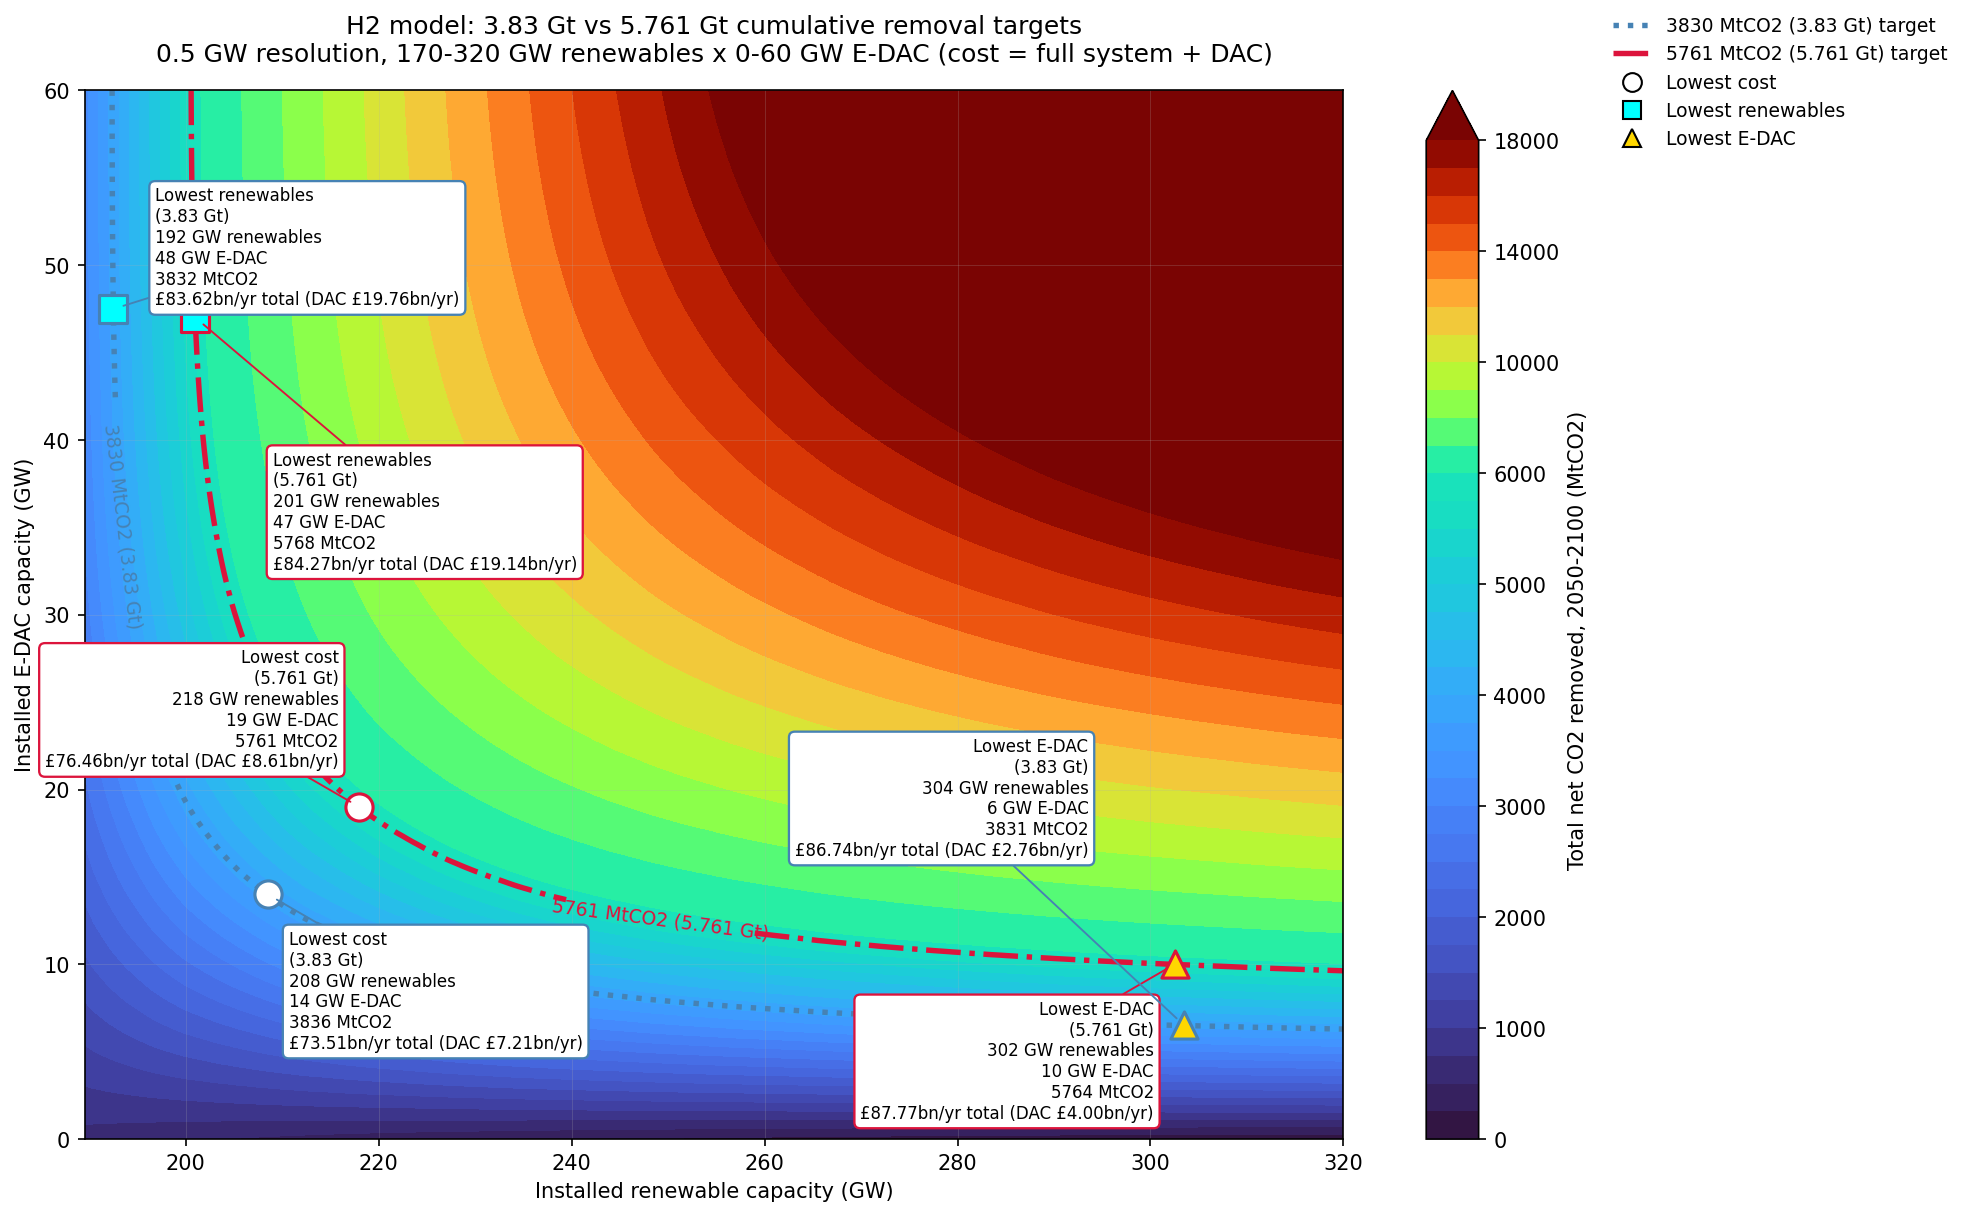

In [4]:

import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox

# Defensive guard: close any stray open figures before creating this cell's
# own, in case cells get re-run out of order.
plt.close("all")

# Comparing two cumulative removal targets side by side: 3830 MtCO2
# (3.83 Gt) and 5761 MtCO2 (5.761 Gt), over the narrow, high-resolution grid
# built above. "Lowest cost" is ranked by total_cost_gbp_yr (full power
# system + DAC), not DAC-only cost, since DAC-only cost ignores the (often
# dominant) cost of the renewable capacity that feeds it.
TARGET_SPECS = [
    (3830, "3.83 Gt", "steelblue", ":"),
    (5761, "5.761 Gt", "crimson", "-."),
]

POINT_TYPE_MARKER = {"Lowest cost": "o", "Lowest renewables": "s", "Lowest E-DAC": "^"}
POINT_TYPE_FACECOLOR = {"Lowest cost": "white", "Lowest renewables": "cyan", "Lowest E-DAC": "gold"}
COMBINED_MARKER = "D"
COMBINED_FACECOLOR = "silver"

# Colour scale: dense levels near the targets (0-6000 MtCO2, where both
# targets sit) for maximum contrast right where it matters, then coarser
# levels further out (6000-18000) so the excess-removal region keeps fading
# instead of being one large flat block of the colormap's top colour.
# Anything above 18000 still gets the top colour (colorbar "extend" arrow),
# but that's now a small corner of the grid, not most of it. "turbo" gives
# the full purple -> blue -> green -> yellow -> orange -> red progression,
# and contourf's explicit levels give each of the two bands an equal share
# of that progression regardless of its value span, so the low, fine-grained
# band (0-6000) sweeps purple through yellow while the coarser high band
# (6000-18000) sweeps orange through red.
VMAX_MTCO2 = 6000
VMAX_FADE_MTCO2 = 18000
color_levels = np.concatenate(
    [
        np.linspace(0, VMAX_MTCO2, 25),
        np.linspace(VMAX_MTCO2, VMAX_FADE_MTCO2, 13)[1:],
    ]
)
COLOR_CMAP = "turbo"

plot_df_cmp = grid_table.copy()
plot_df_cmp = plot_df_cmp[
    plot_df_cmp["renewables_gw"].notna()
    & plot_df_cmp["e_dac_capacity_gw"].notna()
    & plot_df_cmp["total_net_removed_2050_2100_mtco2"].notna()
]

pivot_removed_cmp = plot_df_cmp.pivot_table(
    index="e_dac_capacity_gw",
    columns="renewables_gw",
    values="total_net_removed_2050_2100_mtco2",
    aggfunc="mean",
)

x_cmp = pivot_removed_cmp.columns.to_numpy(dtype=float)
y_cmp = pivot_removed_cmp.index.to_numpy(dtype=float)
z_cmp = pivot_removed_cmp.to_numpy(dtype=float)

# Collect the three optimal points ("Lowest cost", "Lowest renewables",
# "Lowest E-DAC") for each target.
candidate_rows = []
for target_mtco2, target_label, target_color, target_linestyle in TARGET_SPECS:
    meeting_df = plot_df_cmp[plot_df_cmp["total_net_removed_2050_2100_mtco2"] >= target_mtco2]

    if meeting_df.empty:
        print(f"No scenarios meet {target_mtco2} MtCO2 ({target_label}) in the searched grid.")
        continue

    point_specs = [
        (
            "Lowest cost",
            meeting_df.sort_values(["total_cost_gbp_yr", "renewables_gw", "e_dac_capacity_gw"]).iloc[0],
        ),
        (
            "Lowest renewables",
            meeting_df.sort_values(["renewables_gw", "e_dac_capacity_gw", "total_cost_gbp_yr"]).iloc[0],
        ),
        (
            "Lowest E-DAC",
            meeting_df.sort_values(["e_dac_capacity_gw", "renewables_gw", "total_cost_gbp_yr"]).iloc[0],
        ),
    ]

    for point_type, row in point_specs:
        candidate_rows.append(
            {
                "renewables_gw": row["renewables_gw"],
                "e_dac_capacity_gw": row["e_dac_capacity_gw"],
                "total_net_removed_2050_2100_mtco2": row["total_net_removed_2050_2100_mtco2"],
                "total_cost_gbp_yr": row["total_cost_gbp_yr"],
                "dac_cost_gbp_yr": row["dac_cost_gbp_yr"],
                "target_label": target_label,
                "target_color": target_color,
                "point_type": point_type,
            }
        )

fig, ax = plt.subplots(figsize=(13, 8), layout="constrained")

contour = ax.contourf(x_cmp, y_cmp, z_cmp, levels=color_levels, cmap=COLOR_CMAP, extend="max")

if not candidate_rows:
    print("No scenarios meet either target in the searched grid; nothing to plot.")
else:
    candidates_df = pd.DataFrame(candidate_rows)

    # Points that coincide (same grid cell) get merged into a single marker
    # with a combined label, instead of stacking separate labels on top of
    # each other -- this is what happened for "Lowest cost"/"Lowest
    # renewables" in the single-target plot above.
    def _unique_sorted(series: pd.Series) -> list[str]:
        return sorted(set(series))

    merged_points = candidates_df.groupby(["renewables_gw", "e_dac_capacity_gw"], as_index=False).agg(
        total_net_removed_2050_2100_mtco2=("total_net_removed_2050_2100_mtco2", "first"),
        total_cost_gbp_yr=("total_cost_gbp_yr", "first"),
        dac_cost_gbp_yr=("dac_cost_gbp_yr", "first"),
        point_types=("point_type", _unique_sorted),
        target_labels=("target_label", _unique_sorted),
        target_colors=("target_color", _unique_sorted),
    )

    # Zoom the axes onto the marked points instead of the full 150-650 x
    # 0-150 grid, so the target lines and dots sit near the middle of the
    # plot rather than crammed into a corner.
    ren_vals = merged_points["renewables_gw"].to_numpy(dtype=float)
    edac_vals = merged_points["e_dac_capacity_gw"].to_numpy(dtype=float)

    ren_pad = max(50.0, (ren_vals.max() - ren_vals.min()) * 0.7)
    edac_pad = max(20.0, (edac_vals.max() - edac_vals.min()) * 0.7)

    xlim = (
        max(x_cmp.min(), ren_vals.min() - ren_pad),
        min(x_cmp.max(), ren_vals.max() + ren_pad),
    )
    ylim = (
        max(y_cmp.min(), edac_vals.min() - edac_pad),
        min(y_cmp.max(), edac_vals.max() + edac_pad),
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    # Draw target contour lines + inline labels *after* zooming, so clabel
    # places its inline text within the visible (zoomed) window.
    for target_idx, (target_mtco2, target_label, target_color, target_linestyle) in enumerate(TARGET_SPECS):
        if target_label not in set(candidates_df["target_label"]):
            continue
        target_line = ax.contour(
            x_cmp,
            y_cmp,
            z_cmp,
            levels=[target_mtco2],
            colors=target_color,
            linewidths=2.6,
            linestyles=target_linestyle,
        )
        # Targets that sit close together would otherwise get their inline
        # labels auto-placed at nearly the same spot by clabel's default
        # heuristic. Spread each target's label to
        # a different point along its own line instead, using its "Lowest
        # renewables"/"Lowest E-DAC" optimal points (the line's visible
        # x-span) to build a manual guess point -- clabel snaps this to the
        # nearest actual vertex on the contour, so the guess only needs to
        # be roughly on the line.
        target_rows = candidates_df[candidates_df["target_label"] == target_label]
        lo_row = target_rows.loc[target_rows["renewables_gw"].idxmin()]
        hi_row = target_rows.loc[target_rows["renewables_gw"].idxmax()]
        x_lo, x_hi = lo_row["renewables_gw"], hi_row["renewables_gw"]
        label_frac = 0.25 + 0.25 * target_idx
        manual_x = x_lo + label_frac * (x_hi - x_lo)
        manual_y = (
            lo_row["e_dac_capacity_gw"]
            + (manual_x - x_lo) / (x_hi - x_lo) * (hi_row["e_dac_capacity_gw"] - lo_row["e_dac_capacity_gw"])
            if x_hi > x_lo
            else lo_row["e_dac_capacity_gw"]
        )
        ax.clabel(
            target_line,
            fmt={target_mtco2: f"{target_mtco2} MtCO2 ({target_label})"},
            inline=True,
            fontsize=9,
            manual=[(manual_x, manual_y)],
        )

    # Marker footprints go in first, so labels avoid the dots as well as
    # each other.
    placed_boxes: list[Bbox] = []
    marker_specs = []
    any_combined_point_types = False

    for _, row in merged_points.iterrows():
        point_types = row["point_types"]
        target_colors = row["target_colors"]
        target_labels = row["target_labels"]

        if len(point_types) == 1:
            marker = POINT_TYPE_MARKER[point_types[0]]
            facecolor = POINT_TYPE_FACECOLOR[point_types[0]]
        else:
            marker = COMBINED_MARKER
            facecolor = COMBINED_FACECOLOR
            any_combined_point_types = True

        edgecolor = target_colors[0] if len(target_colors) == 1 else "black"
        linewidth = 1.5 if len(target_colors) == 1 else 2.2

        xy = (row["renewables_gw"], row["e_dac_capacity_gw"])

        ax.scatter(
            *xy,
            marker=marker,
            facecolor=facecolor,
            edgecolor=edgecolor,
            s=170,
            linewidth=linewidth,
            zorder=7,
        )

        label_text = (
            f"{' & '.join(point_types)}\n"
            f"({' & '.join(target_labels)})\n"
            f"{row['renewables_gw']:.0f} GW renewables\n"
            f"{row['e_dac_capacity_gw']:.0f} GW E-DAC\n"
            f"{row['total_net_removed_2050_2100_mtco2']:.0f} MtCO2\n"
            f"£{row['total_cost_gbp_yr'] / 1e9:.2f}bn/yr total "
            f"(DAC £{row['dac_cost_gbp_yr'] / 1e9:.2f}bn/yr)"
        )

        marker_specs.append((xy, label_text, edgecolor))

        marker_px = ax.transData.transform(xy)
        half = 11
        placed_boxes.append(
            Bbox([[marker_px[0] - half, marker_px[1] - half], [marker_px[0] + half, marker_px[1] + half]])
        )

    # Place each label at the first non-overlapping candidate offset on a
    # ring around its point, expanding the ring outward until it finds a
    # free spot (bounded), so no two label boxes -- or a label and a marker
    # -- ever overlap. Boxes are padded by a few pixels before the overlap
    # test so accepted placements keep a visible gap, not just a bare
    # non-touching edge.
    def _padded(bbox: Bbox, pad: float = 6.0) -> Bbox:
        return Bbox([[bbox.x0 - pad, bbox.y0 - pad], [bbox.x1 + pad, bbox.y1 + pad]])

    def _annotation_extent(annotation) -> Bbox:
        # Annotation.get_window_extent() measures only the text glyphs, not
        # the rounded box patch drawn around them -- use the patch's own
        # extent (what is actually visible) so the collision check matches
        # what the reader sees.
        patch = annotation.get_bbox_patch()
        if patch is not None:
            return patch.get_window_extent(renderer=renderer)
        return annotation.get_window_extent(renderer=renderer)

    placed_boxes = [_padded(b) for b in placed_boxes]

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    angles = [i * 30 for i in range(12)]

    # Keep every label inside the axes -- without this a label can be pushed
    # past the plot edge (over the axis labels/ticks, or off the figure
    # entirely) while still counting as "non-overlapping".
    axes_bounds = ax.get_window_extent(renderer=renderer)

    def _within_axes(bbox: Bbox) -> bool:
        return (
            bbox.x0 >= axes_bounds.x0
            and bbox.x1 <= axes_bounds.x1
            and bbox.y0 >= axes_bounds.y0
            and bbox.y1 <= axes_bounds.y1
        )

    for xy, text, edgecolor in marker_specs:
        chosen_bbox = None
        radius = 20.0
        while chosen_bbox is None and radius <= 160.0:
            for angle in angles:
                rad = math.radians(angle)
                dx, dy = radius * math.cos(rad), radius * math.sin(rad)
                ann = ax.annotate(
                    text,
                    xy=xy,
                    xytext=(dx, dy),
                    textcoords="offset points",
                    fontsize=8,
                    ha="left" if dx >= 0 else "right",
                    va="bottom" if dy >= 0 else "top",
                    bbox={
                        "boxstyle": "round,pad=0.35",
                        "facecolor": "white",
                        "edgecolor": edgecolor,
                        "alpha": 1.0,
                        "linewidth": 1.1,
                    },
                    arrowprops={
                        "arrowstyle": "-",
                        "color": edgecolor,
                        "linewidth": 0.9,
                        "shrinkA": 0,
                        "shrinkB": 5,
                    },
                    zorder=8,
                )
                fig.canvas.draw()
                bbox = _padded(_annotation_extent(ann))
                if _within_axes(bbox) and not any(bbox.overlaps(pb) for pb in placed_boxes):
                    chosen_bbox = bbox
                    break
                ann.remove()
            if chosen_bbox is None:
                radius += 18.0

        if chosen_bbox is None:
            # No fully clear (in-bounds AND non-overlapping) spot found
            # within the search radius (very crowded case). Relax to
            # "in-bounds" only -- staying inside the axes matters more than
            # a small residual overlap -- and fall back further to simply
            # in-bounds-clamped as an absolute last resort, so a label is
            # never silently dropped or pushed off the figure.
            best_ann, best_bbox = None, None
            for test_radius in (radius, 160.0, 110.0, 60.0, 20.0):
                for angle in angles:
                    rad = math.radians(angle)
                    dx, dy = test_radius * math.cos(rad), test_radius * math.sin(rad)
                    ann = ax.annotate(
                        text,
                        xy=xy,
                        xytext=(dx, dy),
                        textcoords="offset points",
                        fontsize=8,
                        ha="left" if dx >= 0 else "right",
                        va="bottom" if dy >= 0 else "top",
                        bbox={
                            "boxstyle": "round,pad=0.35",
                            "facecolor": "white",
                            "edgecolor": edgecolor,
                            "alpha": 1.0,
                            "linewidth": 1.1,
                        },
                        arrowprops={
                            "arrowstyle": "-",
                            "color": edgecolor,
                            "linewidth": 0.9,
                            "shrinkA": 0,
                            "shrinkB": 5,
                        },
                        zorder=8,
                    )
                    fig.canvas.draw()
                    bbox = _padded(_annotation_extent(ann))
                    if _within_axes(bbox):
                        best_ann, best_bbox = ann, bbox
                        break
                    ann.remove()
                if best_ann is not None:
                    break

            # Nothing tried landed fully in-bounds (very unlikely): keep the
            # last attempt so the label is still present near its point,
            # rather than raising or silently dropping it.
            chosen_bbox = best_bbox if best_ann is not None else bbox

        placed_boxes.append(chosen_bbox)

    target_line_handles = [
        Line2D(
            [0],
            [0],
            color=target_color,
            linestyle=target_linestyle,
            linewidth=2.6,
            label=f"{target_mtco2} MtCO2 ({target_label}) target",
        )
        for target_mtco2, target_label, target_color, target_linestyle in TARGET_SPECS
        if target_label in set(candidates_df["target_label"])
    ]
    point_type_handles = [
        Line2D(
            [0],
            [0],
            marker=marker,
            linestyle="",
            markerfacecolor=facecolor,
            markeredgecolor="black",
            markersize=9,
            label=point_type,
        )
        for point_type, marker, facecolor in [
            ("Lowest cost", "o", "white"),
            ("Lowest renewables", "s", "cyan"),
            ("Lowest E-DAC", "^", "gold"),
        ]
    ]
    combined_handle = (
        [
            Line2D(
                [0],
                [0],
                marker=COMBINED_MARKER,
                linestyle="",
                markerfacecolor=COMBINED_FACECOLOR,
                markeredgecolor="black",
                markersize=9,
                label="Multiple criteria coincide",
            )
        ]
        if any_combined_point_types
        else []
    )

    fig.legend(
        handles=[*target_line_handles, *point_type_handles, *combined_handle],
        loc="outside right upper",
        fontsize=9,
    )

colorbar = fig.colorbar(contour, ax=ax)
colorbar.set_label("Total net CO2 removed, 2050-2100 (MtCO2)")

ax.set_title(
    "H2 model: 3.83 Gt vs 5.761 Gt cumulative removal targets\n"
    "0.5 GW resolution, 170-320 GW renewables x 0-60 GW E-DAC (cost = full system + DAC)",
    pad=14,
)
ax.set_xlabel("Installed renewable capacity (GW)")
ax.set_ylabel("Installed E-DAC capacity (GW)")
ax.grid(True, alpha=0.25)

plt.show()